In [1]:
!pip install numpy pandas matplotlib scikit-learn pillow tqdm

!pip install tensorflow-addons
!pip install seaborn
!pip install split-folders
!pip install streamlit
!pip install kaggle

ERROR: Could not find a version that satisfies the requirement tensorflow-addons (from versions: none)
ERROR: No matching distribution found for tensorflow-addons
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 97.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 142.0 MB/s eta 0:00:00


In [2]:
!pip install tensorflow

In [3]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [4]:
!kaggle datasets download -d feyzazkefe/trashnet


Dataset URL: https://www.kaggle.com/datasets/feyzazkefe/trashnet
License(s): unknown
  0% 0.00/40.8M [00:00<?, ?B/s]
100% 40.8M/40.8M [00:00<00:00, 1.73GB/s]


In [5]:
!unzip trashnet.zip -d trashnet

Archive:  trashnet.zip
  inflating: trashnet/dataset-resized/cardboard/cardboard1.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard10.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard100.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard101.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard102.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard103.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard104.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard105.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard106.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard107.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard108.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard109.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard11.jpg  
  inflating: trashnet/dataset-resized/cardboard/cardboard110.jpg  
  inflating: trashnet/dataset-resized/cardb

In [6]:
import os
from collections import Counter
# Count images in each class folder
class_counts = {}
for cls in sorted(os.listdir('trashnet/dataset-resized')):
    cls_path = os.path.join('trashnet/dataset-resized', cls)
    if os.path.isdir(cls_path):
        count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('jpg', 'jpeg', 'png'))])
        class_counts[cls] = count
print("TOTAL IMAGES PER CLASS:")
for k, v in class_counts.items():
    print(f"{k}: {v}")
# Find average or target count
target_count = int(400)
print("\nTarget per class:", target_count)



TOTAL IMAGES PER CLASS:
cardboard: 403
glass: 501
metal: 410
paper: 594
plastic: 482
trash: 137

Target per class: 400


In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img, array_to_img
import numpy as np
import random
from tqdm import tqdm

datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8,1.2],
    fill_mode='nearest'
)

# Augment underrepresented classes
for cls, count in class_counts.items():
    if count < target_count:
        print(f"\nAugmenting class: {cls} ({count} → {target_count})")
        cls_dir = os.path.join('trashnet/dataset-resized', cls)
        images = [os.path.join(cls_dir, f) for f in os.listdir(cls_dir) if f.lower().endswith(('jpg','jpeg','png'))]

        n_needed = target_count - count
        i = 0

        for img_path in tqdm(images):
            if i >= n_needed:
                break
            img = load_img(img_path)
            x = img_to_array(img)
            x = np.expand_dims(x, axis=0)
            # Generate a few augmented copies per image
            for batch in datagen.flow(x, batch_size=1, save_to_dir=cls_dir, save_prefix='aug', save_format='jpg'):
                i += 1
                if i >= n_needed:
                    break
        print(f"Done: added {n_needed} images to {cls}")


Augmenting class: trash (137 → 400)


  1%|          | 1/137 [00:12<28:31, 12.59s/it]

Done: added 263 images to trash


In [8]:
print("\nAfter augmentation:")
for cls in sorted(os.listdir('trashnet/dataset-resized')):
    cls_path = os.path.join('trashnet/dataset-resized', cls)
    if os.path.isdir(cls_path):
        count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('jpg','jpeg','png'))])
        print(f"{cls}: {count}")


After augmentation:
cardboard: 403
glass: 501
metal: 410
paper: 594
plastic: 482
trash: 396


In [9]:
import splitfolders
input_folder = 'trashnet/dataset-resized'  # adapt if path differs
output = "data_split"
splitfolders.ratio(input_folder, output=output, seed=1337, ratio=(.8, .1, .1))

Copying files: 2786 files [00:00, 9645.55 files/s]


In [10]:
import os
from collections import Counter, defaultdict

def count_images_in_folders(base_dir):
    counts = {}
    for cls in sorted(os.listdir(base_dir)):
        cls_path = os.path.join(base_dir, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

# Dictionary to store total counts per class
total_counts = defaultdict(int)

for split in ["train", "val", "test"]:
    counts = count_images_in_folders(f"data_split/{split}")
    print(f"\n{split.upper()} SET CLASS COUNTS:")
    print(Counter(counts))
    # Add to total counts
    for cls, cnt in counts.items():
        total_counts[cls] += cnt

# Print total images per class
print("\nTOTAL IMAGES PER CLASS:")
for cls, cnt in sorted(total_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"{cls}: {cnt}")


TRAIN SET CLASS COUNTS:
Counter({'paper': 475, 'glass': 400, 'plastic': 385, 'metal': 328, 'cardboard': 322, 'trash': 316})

VAL SET CLASS COUNTS:
Counter({'paper': 59, 'glass': 50, 'plastic': 48, 'metal': 41, 'cardboard': 40, 'trash': 39})

TEST SET CLASS COUNTS:
Counter({'paper': 60, 'glass': 51, 'plastic': 49, 'cardboard': 41, 'metal': 41, 'trash': 41})

TOTAL IMAGES PER CLASS:
paper: 594
glass: 501
plastic: 482
metal: 410
cardboard: 403
trash: 396


In [11]:
import tensorflow as tf
from keras import layers

def get_datasets(batch_size=32, img_size=(224, 224)):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        "data_split/train",
        image_size=img_size,
        batch_size=batch_size,
        label_mode="int",
        shuffle=True,
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        "data_split/val",
        image_size=img_size,
        batch_size=batch_size,
        label_mode="int",
        shuffle=False,
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        "data_split/test",
        image_size=img_size,
        batch_size=batch_size,
        label_mode="int",
        shuffle=False,
    )

    class_names = train_ds.class_names

    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

    return train_ds, val_ds, test_ds, class_names


Found 2226 files belonging to 6 classes.
Found 277 files belonging to 6 classes.
Found 283 files belonging to 6 classes.
Original classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Using remapped classes: ['recyclables', 'paper', 'general_waste']
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         2,883 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,999,235 (11.44 MB)

 Trainable params: 2,883 (11.26 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

Class weights: {0: 0.6666666666666666, 1: 0.93099121706399, 2: 2.348101265822785}
Epoch 1/10
     70/Unknown 14s 54ms/step - accuracy: 0.3949 - loss: 1.3651

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_accuracy improved from -inf to 0.56679, saving model to best_model.keras
70/70 ━━━━━━━━━━━━━━━━━━━━ 17s 98ms/step - accuracy: 0.3956 - loss: 1.3633 - val_accuracy: 0.5668 - val_loss: 0.9371 - learning_rate: 1.0000e-04
Epoch 2/10
69/70 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5551 - loss: 0.9282
Epoch 2: val_accuracy improved from 0.56679 to 0.74729, saving model to best_model.keras
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.5566 - loss: 0.9269 - val_accuracy: 0.7473 - val_loss: 0.6690 - learning_rate: 1.0000e-04
Epoch 3/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.6961 - loss: 0.7178
Epoch 3: val_accuracy improved from 0.74729 to 0.83032, saving model to best_model.keras
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.6965 - loss: 0.7175 - val_accuracy: 0.8303 - val_loss: 0.5381 - learning_rate: 1.0000e-04
Epoch 4/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7733 - loss: 0.5677
Epoch 4: val_accuracy improved from 0.83032 to 

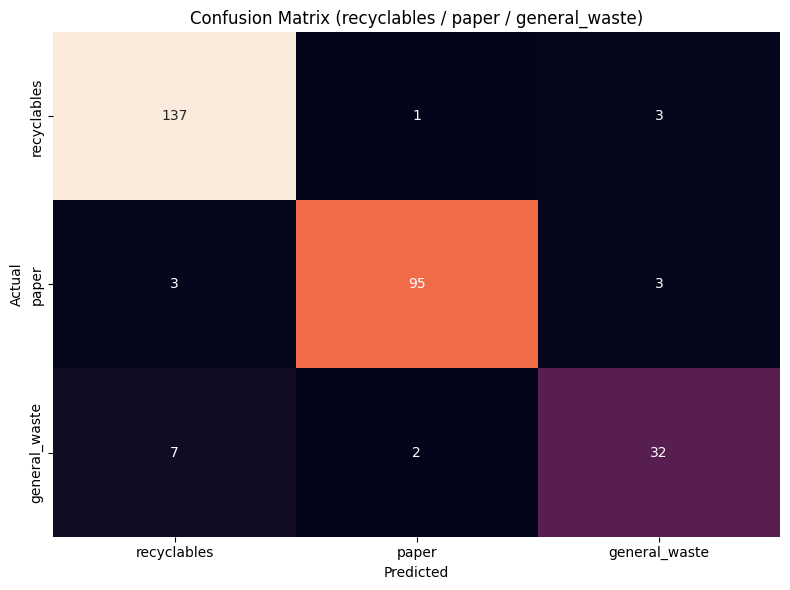

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_203']]
Received: inputs=['Tensor(shape=(1, 224, 224, 3))']
  warnings.warn(msg)


KeyError: "Exception encountered when calling Functional.call().\n\n\x1b[1m135165917429008\x1b[0m\n\nArguments received by Functional.call():\n  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)\n  • training=False\n  • mask=None\n  • kwargs=<class 'inspect._empty'>"

In [12]:
# =================== MobileNetV3-Large (TrashNet 6 -> 3 classes) ===================
import os, numpy as np, matplotlib.pyplot as plt, seaborn as sns, tensorflow as tf
from keras import layers, Model
from keras.applications import MobileNetV3Large
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.get_logger().setLevel('ERROR')
AUTOTUNE = tf.data.AUTOTUNE
SEED = 1337
IMG_SIZE = (224, 224)
BATCH = 32

# ------------------------------------------------------------
# 1) Load dataset  (expects get_datasets is already defined)
# ------------------------------------------------------------
train_ds, val_ds, test_ds, class_names = get_datasets(batch_size=BATCH, img_size=IMG_SIZE)
print("Original classes:", class_names)

# ------------------------------------------------------------
# 2) Remap 6 -> 3 classes (Option A: filter uses tf.reduce_all)
#    recyclables=0  (glass, metal, plastic)
#    paper=1        (paper,cardboard)
#    general_waste=2(trash)
# ------------------------------------------------------------
NEW_CLASS_NAMES = ['recyclables', 'paper', 'general_waste']
name_to_new = {'cardboard':1, 'glass':0, 'metal':0, 'plastic':0, 'paper':1, 'trash':2}

ORIG = class_names
keys = tf.constant([ORIG.index(k) for k in name_to_new.keys()], dtype=tf.int64)
vals = tf.constant([name_to_new[k] for k in name_to_new.keys()], dtype=tf.int64)
lut  = tf.lookup.StaticHashTable(
    tf.lookup.KeyValueTensorInitializer(keys, vals),
    default_value=-1
)

def remap(ds):
    def _map(x, y):
        y = tf.cast(y, tf.int64)
        y_new = lut.lookup(y)
        return x, y_new
    ds = ds.map(_map, num_parallel_calls=AUTOTUNE)
    # filter must return a single boolean scalar per *batch*
    ds = ds.filter(lambda x, y: tf.reduce_all(y >= 0))
    return ds.prefetch(AUTOTUNE)

train_ds = remap(train_ds)
val_ds   = remap(val_ds)
test_ds  = remap(test_ds)

class_names = NEW_CLASS_NAMES
num_classes = len(class_names)
print("Using remapped classes:", class_names)

# ------------------------------------------------------------
# 3) Data augmentation (version-safe brightness)
# ------------------------------------------------------------
def _rand_brightness(img):
    return tf.image.stateless_random_brightness(img, max_delta=0.2, seed=[SEED, 0])

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.Lambda(_rand_brightness, name="RandomBrightness"),
], name="data_augmentation")

# ------------------------------------------------------------
# 4) Model: MobileNetV3-Large (transfer learning)
# ------------------------------------------------------------
base_model = MobileNetV3Large(include_top=False, input_shape=IMG_SIZE+(3,), weights="imagenet")
base_model.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE+(3,))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v3.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)
model = Model(inputs, outputs)

model.compile(optimizer=Adam(1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

# ------------------------------------------------------------
# 5) Callbacks
# ------------------------------------------------------------
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)

# ------------------------------------------------------------
# 6) Class weights (AFTER remap)
# ------------------------------------------------------------
train_labels = np.array([int(y.numpy()) for _, y in train_ds.unbatch()])
class_weights = compute_class_weight('balanced', classes=np.arange(num_classes), y=train_labels)
class_weight_dict = {i: float(w) for i, w in enumerate(class_weights)}
print("Class weights:", class_weight_dict)

# ------------------------------------------------------------
# 7) Train (frozen) -> Fine-tune (unfreeze top ~50, skip BN)
# ------------------------------------------------------------
history = model.fit(
    train_ds, validation_data=val_ds, epochs=10,
    class_weight=class_weight_dict, callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

base_model.trainable = True
set_trainable = 0
for layer in base_model.layers[-50:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True
        set_trainable += 1
print(f"Unfroze ~last 50 layers (trainable set = {set_trainable})")

model.compile(optimizer=Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

fine_tune_history = model.fit(
    train_ds, validation_data=val_ds, epochs=20,
    initial_epoch=len(history.history['loss']),
    class_weight=class_weight_dict, callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

# ------------------------------------------------------------
# 8) Evaluation
# ------------------------------------------------------------
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"Test Accuracy: {test_acc*100:.2f}% | Loss: {test_loss:.4f}")

y_true, y_pred = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true += labels.numpy().tolist()
    y_pred += np.argmax(preds, axis=1).tolist()

print("\nClassification Report (3-class):")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cbar=False,
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix (recyclables / paper / general_waste)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 9) Grad-CAM (auto-detect last conv; no hard-coded names)
# ------------------------------------------------------------
def find_last_conv_layer(m):
    for layer in reversed(m.layers):
        if isinstance(layer, tf.keras.Model):
            inner = find_last_conv_layer(layer)
            if inner is not None:
                return inner
        if isinstance(layer, (layers.Conv2D, tf.keras.layers.SeparableConv2D, tf.keras.layers.DepthwiseConv2D)):
            return layer
    return None

last_conv_layer = find_last_conv_layer(model)
assert last_conv_layer is not None, "No conv layer found for Grad-CAM."

def make_gradcam_heatmap(img_array, model, conv_layer):
    grad_model = Model([model.inputs], [conv_layer.output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array, training=False)
        class_idx = tf.argmax(preds[0])       # use predicted class
        loss = preds[:, class_idx]
    grads = tape.gradient(loss, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0,1,2))
    conv_out = conv_out[0]
    heatmap = tf.reduce_mean(conv_out * pooled, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= (tf.reduce_max(heatmap) if tf.reduce_max(heatmap) > 0 else 1e-12)
    return heatmap.numpy()

# Example: visualize one test image
for images, labels in test_ds.take(1):
    hm = make_gradcam_heatmap(images[0:1], model, last_conv_layer)
    plt.figure(figsize=(9,3))
    plt.subplot(1,2,1); plt.imshow(tf.cast(images[0], tf.uint8)); plt.title("Image"); plt.axis("off")
    plt.subplot(1,2,2); plt.imshow(hm, cmap='jet'); plt.title("Grad-CAM"); plt.axis("off")
    plt.tight_layout(); plt.show()
    break

# ------------------------------------------------------------
# 10) Save model + labels
# ------------------------------------------------------------
model.save("trashnet_v3_3class.keras")
with open("class_labels_3class.txt", "w") as f:
    for c in class_names: f.write(c + "\n")
print("Saved: trashnet_v3_3class.keras, class_labels_3class.txt")

In [13]:
from keras.applications.mobilenet_v3 import preprocess_input
train_image_generator = datagen.flow_from_directory(
                                            "/content/data_split/train",
                                            target_size=(224, 224), # Resize all images to 224x224
                                            batch_size= 32, # Number of images per batch
                                            class_mode='categorical') # Multi-class classification


# Validation images (no augmentation, only preprocessing)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
val_image_generator = val_datagen.flow_from_directory(
                                            "/content/data_split/val",
                                            target_size=(224, 224),
                                            batch_size= 32,
                                            class_mode='categorical')

Found 2226 images belonging to 6 classes.
Found 277 images belonging to 6 classes.


In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Assumes you already have:
# model = tf.keras.models.load_model("trashnet_v3_3class.keras")  # or your current model variable
# class_names = ["recyclables", "paper", "general_waste"]         # or loaded from file
# IMG_SIZE = (224, 224)

def PredictImageFromPath(image_path, actual=None,
                         model_obj=None,
                         labels=None,
                         img_size=(224,224)):
    """
    image_path: path to image file
    actual: optional string label for display
    model_obj: keras model object (defaults to global 'model' if None)
    labels: list of class names (defaults to global 'class_names' if None)
    img_size: (W,H), default (224,224)
    """
    # fall back to globals if not passed
    m = model_obj if model_obj is not None else model
    names = labels if labels is not None else class_names

    # 1) Load & preprocess
    img = tf.keras.utils.load_img(image_path, target_size=img_size)
    x = tf.keras.utils.img_to_array(img)
    x = tf.expand_dims(x, 0)  # (1,H,W,3)
    x = tf.keras.applications.mobilenet_v3.preprocess_input(x)  # <-- MobileNetV3 preprocessing

    # 2) Predict
    probs = m.predict(x, verbose=0)[0]         # (num_classes,)
    idx = int(np.argmax(probs))
    label = names[idx]
    conf = float(probs[idx])

    # 3) Show
    plt.figure(figsize=(4,4))
    plt.imshow(img)
    title_actual = f" | Actual: {actual}" if actual is not None else ""
    plt.title(f"Predicted: {label} ({conf:.2%}){title_actual}")
    plt.axis('off')
    plt.show()

    return {"pred_index": idx, "pred_label": label, "confidence": conf, "probs": probs}


In [15]:
import tensorflow as tf
from keras.saving import register_keras_serializable  # Keras 3+

@register_keras_serializable(package="Custom")
def _rand_brightness(img):
    # must match what you used in training
    return tf.image.stateless_random_brightness(img, max_delta=0.2, seed=[1337, 0])

model = tf.keras.models.load_model(
    "/content/best_model.keras",
    custom_objects={'_rand_brightness': _rand_brightness}
)

class_names = ["recyclables", "paper", "general_waste"]
IMG_SIZE = (224, 224)


In [16]:
import numpy as np
import matplotlib.pyplot as plt

def PredictImageFromPath(image_path, actual=None, model_obj=None, labels=None, img_size=(224,224)):
    m = model_obj if model_obj is not None else model
    names = labels if labels is not None else class_names
    img = tf.keras.utils.load_img(image_path, target_size=img_size)
    x = tf.keras.utils.img_to_array(img)[None, ...]
    x = tf.keras.applications.mobilenet_v3.preprocess_input(x)  # MobileNetV3
    probs = m.predict(x, verbose=0)[0]
    idx = int(np.argmax(probs)); label = names[idx]; conf = float(probs[idx])
    plt.figure(figsize=(4,4)); plt.imshow(img)
    plt.title(f"Predicted: {label} ({conf:.2%})" + (f" | Actual: {actual}" if actual else ""))
    plt.axis('off'); plt.show()
    return {"pred_index": idx, "pred_label": label, "confidence": conf, "probs": probs}


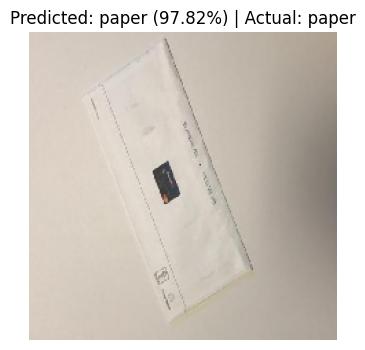

{'pred_index': 1, 'pred_label': 'paper', 'confidence': 0.9781796932220459, 'probs': array([0.01807691, 0.9781797 , 0.00374333], dtype=float32)}


In [17]:
res = PredictImageFromPath("/content/data_split/test/paper/paper11.jpg", actual="paper")
print(res)


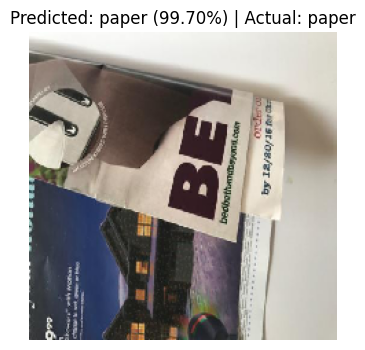

{'pred_index': 1, 'pred_label': 'paper', 'confidence': 0.9969781637191772, 'probs': array([0.00114122, 0.99697816, 0.00188064], dtype=float32)}


In [18]:
res = PredictImageFromPath("/content/data_split/test/paper/paper139.jpg", actual="paper")
print(res)


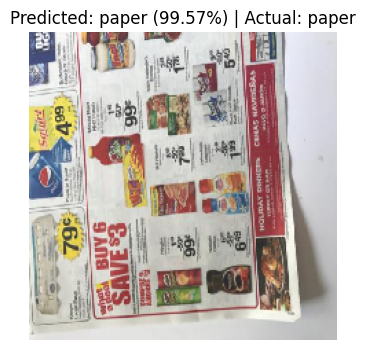

{'pred_index': 1, 'pred_label': 'paper', 'confidence': 0.99574214220047, 'probs': array([3.6049963e-03, 9.9574214e-01, 6.5287756e-04], dtype=float32)}


In [19]:
res = PredictImageFromPath("/content/data_split/test/paper/paper196.jpg", actual="paper")
print(res)


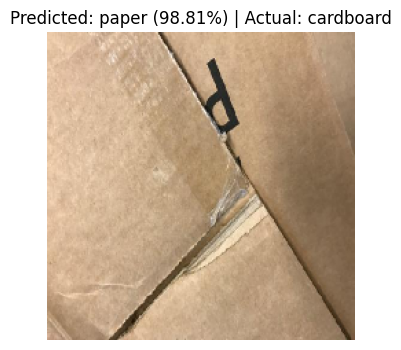

{'pred_index': 1, 'pred_label': 'paper', 'confidence': 0.9880571365356445, 'probs': array([0.00574251, 0.98805714, 0.00620031], dtype=float32)}


In [20]:
res = PredictImageFromPath("/content/data_split/test/cardboard/cardboard107.jpg", actual="cardboard")
print(res)


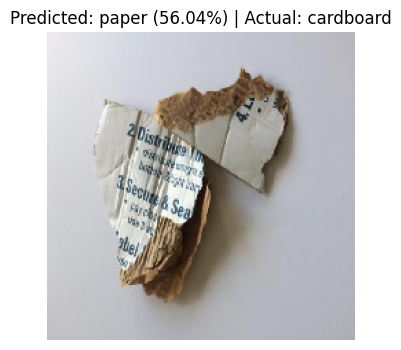

{'pred_index': 1, 'pred_label': 'paper', 'confidence': 0.5603948831558228, 'probs': array([0.03822565, 0.5603949 , 0.40137947], dtype=float32)}


In [21]:
res = PredictImageFromPath("/content/data_split/test/cardboard/cardboard153.jpg", actual="cardboard")
print(res)

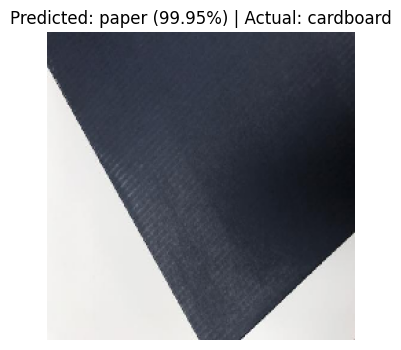

{'pred_index': 1, 'pred_label': 'paper', 'confidence': 0.9995346069335938, 'probs': array([7.2067407e-05, 9.9953461e-01, 3.9336085e-04], dtype=float32)}


In [22]:
res = PredictImageFromPath("/content/data_split/test/cardboard/cardboard268.jpg", actual="cardboard")
print(res)

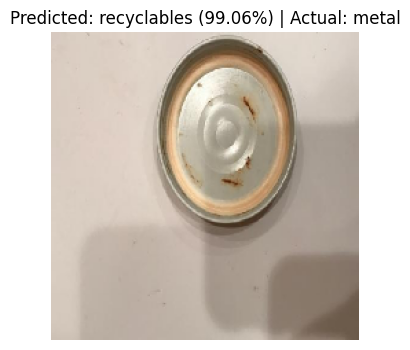

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.9906260967254639, 'probs': array([0.9906261 , 0.00185758, 0.00751632], dtype=float32)}


In [23]:
res = PredictImageFromPath("/content/data_split/test/metal/metal240.jpg", actual="metal")
print(res)


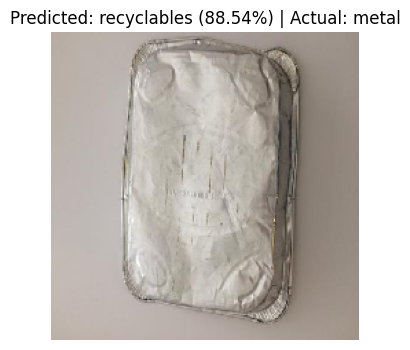

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.8854236602783203, 'probs': array([0.88542366, 0.041827  , 0.07274938], dtype=float32)}


In [24]:
res = PredictImageFromPath("/content/data_split/test/metal/metal175.jpg", actual="metal")
print(res)


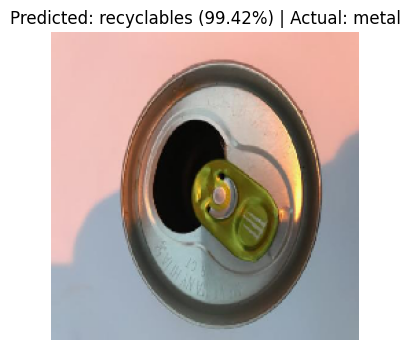

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.994182288646698, 'probs': array([9.9418229e-01, 2.3829614e-04, 5.5793999e-03], dtype=float32)}


In [25]:
res = PredictImageFromPath("/content/data_split/test/metal/metal26.jpg", actual="metal")
print(res)


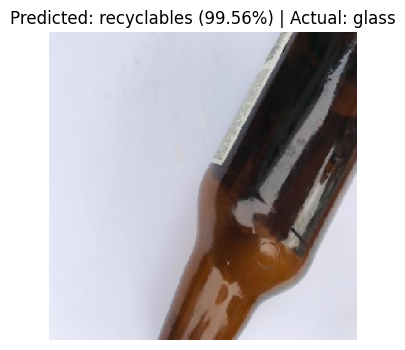

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.9956468939781189, 'probs': array([9.956469e-01, 3.460790e-04, 4.007046e-03], dtype=float32)}


In [26]:
res = PredictImageFromPath("/content/data_split/test/glass/glass129.jpg", actual="glass")
print(res)

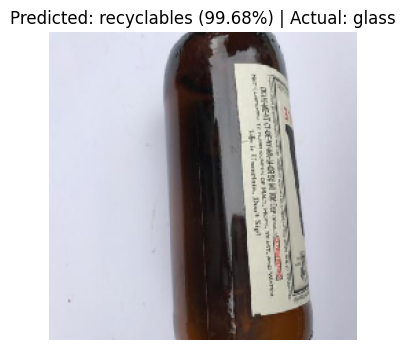

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.9967843294143677, 'probs': array([0.9967843 , 0.00206977, 0.00114589], dtype=float32)}


In [27]:
res = PredictImageFromPath("/content/data_split/test/glass/glass107.jpg", actual="glass")
print(res)

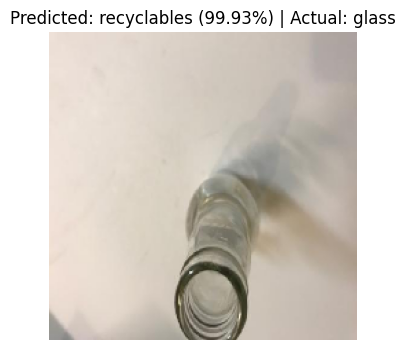

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.9993160963058472, 'probs': array([9.9931610e-01, 4.3994235e-04, 2.4402066e-04], dtype=float32)}


In [28]:
res = PredictImageFromPath("/content/data_split/test/glass/glass276.jpg", actual="glass")
print(res)

In [29]:
res = PredictImageFromPath("/content/data_split/test/trash/aug_0_1241.jpg", actual="trash")
print(res)

FileNotFoundError: [Errno 2] No such file or directory: '/content/data_split/test/trash/aug_0_1241.jpg'

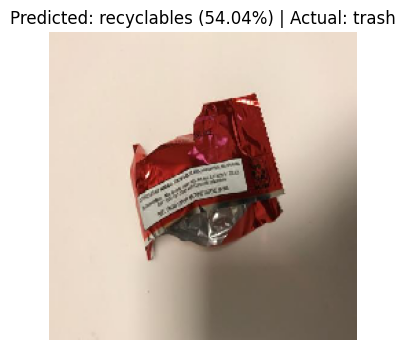

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.5404078364372253, 'probs': array([0.54040784, 0.1498171 , 0.30977505], dtype=float32)}


In [30]:
res = PredictImageFromPath("/content/data_split/test/trash/trash9.jpg", actual="trash")
print(res)

In [31]:
res = PredictImageFromPath("/content/data_split/test/trash/trash67.jpg", actual="trash")
print(res)

FileNotFoundError: [Errno 2] No such file or directory: '/content/data_split/test/trash/trash67.jpg'

In [32]:
res = PredictImageFromPath("/content/data_split/test/trash/trash66.jpg", actual="trash")
print(res)

FileNotFoundError: [Errno 2] No such file or directory: '/content/data_split/test/trash/trash66.jpg'

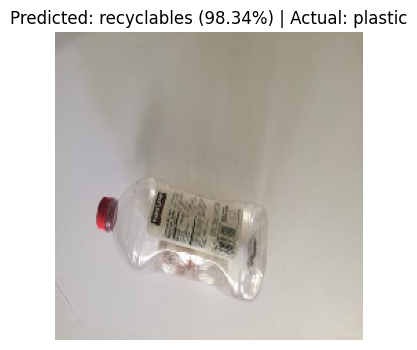

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.9833554625511169, 'probs': array([0.98335546, 0.0028149 , 0.01382966], dtype=float32)}


In [33]:
res = PredictImageFromPath("/content/data_split/test/plastic/plastic129.jpg", actual="plastic")
print(res)

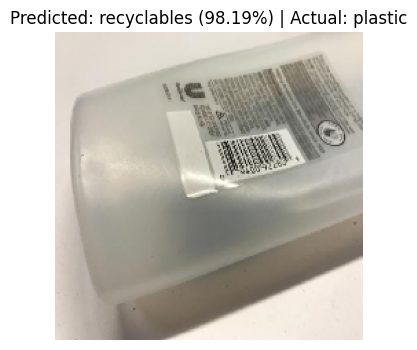

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.9818745851516724, 'probs': array([0.9818746 , 0.01475272, 0.00337271], dtype=float32)}


In [34]:
res = PredictImageFromPath("/content/data_split/test/plastic/plastic175.jpg", actual="plastic")
print(res)

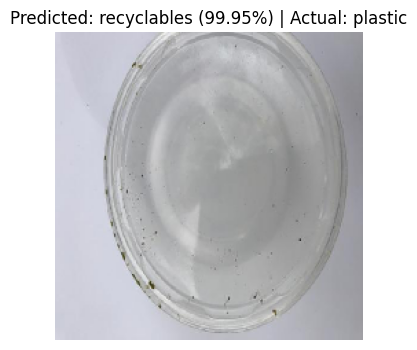

{'pred_index': 0, 'pred_label': 'recyclables', 'confidence': 0.9994696974754333, 'probs': array([9.9946970e-01, 1.6279142e-04, 3.6753391e-04], dtype=float32)}


In [35]:
res = PredictImageFromPath("/content/data_split/test/plastic/plastic212.jpg", actual="plastic")
print(res)

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [37]:
!cp best_model.keras /content/drive/MyDrive/

In [39]:
# ======================================================================
# FULL OPTUNA FINE-TUNING PIPELINE FOR PRETRAINED MobileNetV3-Large
# ======================================================================

!pip install optuna --quiet

import tensorflow as tf
import numpy as np
import optuna
import os

from keras import layers, Model
from keras.optimizers import Adam, RMSprop
from keras.saving import register_keras_serializable

# ----------------------------------------------------------------------
# 1) Custom Brightness (matches training Lambda)
# ----------------------------------------------------------------------
@register_keras_serializable(package="Custom")
def _rand_brightness(img):
    return tf.image.stateless_random_brightness(img, max_delta=0.2, seed=[1337, 0])

# ----------------------------------------------------------------------
# 2) Dataset loader
# ----------------------------------------------------------------------
def get_datasets(batch_size=32, img_size=(224, 224)):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        "data_split/train", image_size=img_size, batch_size=batch_size,
        label_mode="int", shuffle=True
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        "data_split/val", image_size=img_size, batch_size=batch_size,
        label_mode="int", shuffle=False
    )
    test_ds = tf.keras.utils.image_dataset_from_directory(
        "data_split/test", image_size=img_size, batch_size=batch_size,
        label_mode="int", shuffle=False
    )
    AUTOTUNE = tf.data.AUTOTUNE
    return (train_ds.prefetch(AUTOTUNE),
            val_ds.prefetch(AUTOTUNE),
            test_ds.prefetch(AUTOTUNE),
            train_ds.class_names)

# ----------------------------------------------------------------------
# 3) Remap 6 -> 3 classes
# ----------------------------------------------------------------------
NEW_CLASS_NAMES = ["recyclables", "paper", "general_waste"]
name_to_new = {
    "cardboard": 1, "glass": 0, "metal": 0, "plastic": 0,  # recyclables
    "paper": 1,
    "trash": 2,
}

def create_lookup(class_names):
    ORIG = class_names
    keys = tf.constant([ORIG.index(k) for k in name_to_new.keys()], dtype=tf.int64)
    vals = tf.constant([name_to_new[k] for k in name_to_new.keys()], dtype=tf.int64)
    return tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, vals),
        default_value=-1
    )

def remap_ds(ds, lut):
    AUTOTUNE = tf.data.AUTOTUNE
    def _map(x, y):
        return x, lut.lookup(tf.cast(y, tf.int64))
    ds = ds.map(_map, num_parallel_calls=AUTOTUNE)
    ds = ds.filter(lambda x, y: tf.reduce_all(y >= 0))
    return ds.prefetch(AUTOTUNE)

# ----------------------------------------------------------------------
# 4) Load dataset + apply remap
# ----------------------------------------------------------------------
IMG_SIZE = (224, 224)
BATCH = 32

train_ds, val_ds, test_ds, original_classes = get_datasets(BATCH, IMG_SIZE)
lut = create_lookup(original_classes)
train_ds = remap_ds(train_ds, lut)
val_ds   = remap_ds(val_ds, lut)
test_ds  = remap_ds(test_ds, lut)

num_classes = 3

# ----------------------------------------------------------------------
# 5) Load pretrained model (MobileNetV3-Large)
# ----------------------------------------------------------------------
BASE_MODEL_PATH = "/content/best_model.keras"

def load_pretrained():
    return tf.keras.models.load_model(
        BASE_MODEL_PATH,
        custom_objects={'_rand_brightness': _rand_brightness}
    )

def get_backbone(m):
    # Try by name, else fallback to search
    try:
        return m.get_layer("MobileNetV3Large")
    except ValueError:
        for lyr in m.layers:
            if isinstance(lyr, tf.keras.Model) and "MobileNetV3" in lyr.name:
                return lyr
        raise ValueError("Could not find MobileNetV3 backbone.")

def get_aug_layer(m):
    try:
        return m.get_layer("data_augmentation")
    except ValueError:
        return None

# ----------------------------------------------------------------------
# 6) Optuna objective — re-wire explicitly to avoid graph mixing
# ----------------------------------------------------------------------
def objective(trial):
    dense_units     = trial.suggest_int("dense_units", 64, 512, step=64)
    dropout_rate    = trial.suggest_float("dropout", 0.2, 0.5)
    learning_rate   = trial.suggest_float("lr", 1e-6, 1e-4, log=True)
    unfreeze_layers = trial.suggest_int("unfreeze_layers", 20, 80, step=10)
    optimizer_name  = trial.suggest_categorical("optimizer", ["Adam", "RMSprop"])

    base_graph = load_pretrained()
    backbone   = get_backbone(base_graph)
    aug        = get_aug_layer(base_graph)

    # Unfreeze top N (skip BN)
    backbone.trainable = True
    for layer in backbone.layers[-unfreeze_layers:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

    # Re-wire: input -> (aug) -> preprocess -> backbone(..) -> new head
    inp = base_graph.input
    x = inp
    if aug is not None:
        x = aug(x)
    x = tf.keras.applications.mobilenet_v3.preprocess_input(x)
    x = backbone(x, training=True)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    out = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)

    tuned_model = Model(inputs=inp, outputs=out)

    opt = Adam(learning_rate) if optimizer_name == "Adam" else RMSprop(learning_rate)
    tuned_model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    hist = tuned_model.fit(train_ds, validation_data=val_ds, epochs=5, verbose=0)
    return 1.0 - float(np.max(hist.history["val_accuracy"]))

# ----------------------------------------------------------------------
# 7) Run Optuna search
# ----------------------------------------------------------------------
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=8)
print("Best hyperparameters:", study.best_params)
print("Best validation accuracy:", 1 - study.best_value)

# ----------------------------------------------------------------------
# 8) Final training with best parameters (same wiring)
# ----------------------------------------------------------------------
best = study.best_params
dense_units     = best["dense_units"]
dropout_rate    = best["dropout"]
learning_rate   = best["lr"]
unfreeze_layers = best["unfreeze_layers"]
optimizer_name  = best["optimizer"]

base_graph = load_pretrained()
backbone   = get_backbone(base_graph)
aug        = get_aug_layer(base_graph)

backbone.trainable = True
for layer in backbone.layers[-unfreeze_layers:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

inp = base_graph.input
x = inp
if aug is not None:
    x = aug(x)
x = tf.keras.applications.mobilenet_v3.preprocess_input(x)
x = backbone(x, training=True)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(dense_units, activation="relu")(x)
x = layers.Dropout(dropout_rate)(x)
out = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)

final_model = Model(inputs=inp, outputs=out)

opt = Adam(learning_rate) if optimizer_name == "Adam" else RMSprop(learning_rate)
final_model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history = final_model.fit(train_ds, validation_data=val_ds, epochs=20, verbose=1)

test_loss, test_acc = final_model.evaluate(test_ds, verbose=1)
print(f"Test accuracy: {test_acc*100:.2f}% | loss: {test_loss:.4f}")

final_model.save("mobilenetv3_optuna_finetuned.keras")
print("Saved: mobilenetv3_optuna_finetuned.keras")


Found 2226 files belonging to 6 classes.
Found 277 files belonging to 6 classes.
Found 283 files belonging to 6 classes.


[I 2025-11-15 11:45:56,427] A new study created in memory with name: no-name-d1a31403-a16a-42f0-b119-d32966d5f0ae
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
[I 2025-11-15 11:47:54,357] Trial 0 finished with value: 0.07942235469818115 and parameters: {'dense_units': 384, 'dropout': 0.4790899779207641, 'lr': 4.830406973861111e-05, 'unfreeze_layers': 30, 'optimizer': 'Adam'}. Best is trial 0 with value: 0.07942235469818115.
[I 2025-11-15 11:49:49,236] Trial 1 finished with value: 0.07220214605331421 and parameters: {'dense_units': 448, 'dropout': 0.25555867776093966, 'lr': 2.420593462189269e-05, 'unfreeze_layers': 30, 'optimizer': 'Adam'}. Best is trial 1 with value: 0.07220214605331421.
[

Best hyperparameters: {'dense_units': 192, 'dropout': 0.2563832029589947, 'lr': 4.3332272142089576e-05, 'unfreeze_layers': 20, 'optimizer': 'Adam'}
Best validation accuracy: 0.9314079284667969
Epoch 1/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 48s 265ms/step - accuracy: 0.4704 - loss: 1.2117 - val_accuracy: 0.8881 - val_loss: 0.3658
Epoch 2/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 229ms/step - accuracy: 0.9088 - loss: 0.3040 - val_accuracy: 0.9097 - val_loss: 0.2933
Epoch 3/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 228ms/step - accuracy: 0.9381 - loss: 0.2065 - val_accuracy: 0.9242 - val_loss: 0.2713
Epoch 4/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 228ms/step - accuracy: 0.9420 - loss: 0.1650 - val_accuracy: 0.9314 - val_loss: 0.2498
Epoch 5/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 229ms/step - accuracy: 0.9452 - loss: 0.1582 - val_accuracy: 0.9278 - val_loss: 0.2413
Epoch 6/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 228ms/step - accuracy: 0.9526 - loss: 0.1141 - val_accuracy: 0.9278 - val_loss: 0.2441
Epoch 7/20
70/70 ━━━━━━━━━━━━━━━━


Classification Report (3-class):
               precision    recall  f1-score   support

  recyclables     0.9789    0.9858    0.9823       141
        paper     0.9712    1.0000    0.9854       101
general_waste     0.9730    0.8780    0.9231        41

     accuracy                         0.9753       283
    macro avg     0.9743    0.9546    0.9636       283
 weighted avg     0.9753    0.9753    0.9748       283



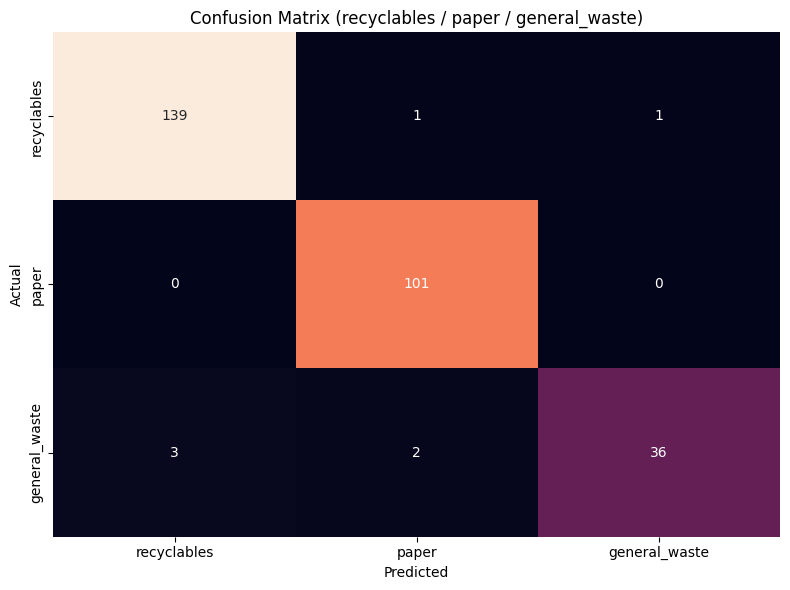

In [48]:
class_names = ["recyclables", "paper", "general_waste"]
y_true, y_pred = [], []
for images, labels in test_ds:
    preds = final_model.predict(images, verbose=0)
    y_true += labels.numpy().tolist()
    y_pred += np.argmax(preds, axis=1).tolist()

print("\nClassification Report (3-class):")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cbar=False,
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix (recyclables / paper / general_waste)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

In [41]:
!cp mobilenetv3_optuna_finetuned.keras /content/drive/MyDrive/

In [42]:
!zip -r data_split_MobileNetv3.zip data_split

In [43]:
!mv data_split_MobileNetv3.zip /content/drive/MyDrive/

In [44]:
!zip -r trashnet_MobileNetv3.zip trashnet

In [45]:
!mv trashnet_MobileNetv3.zip /content/drive/MyDrive/